# Diffusion–RGC hyperparameter analysis across images

This notebook summarizes the folder-level grid search. Every plotted central value is the mean across source images at fixed $(\eta, T)$; uncertainty is the standard error of the mean (SEM) across those images. The translucent bands, error bars, and 3D shells therefore quantify image-to-image variation, not variation across diffusion timesteps.

In [69]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401

plt.rcParams.update({
    'figure.dpi': 130,
    'savefig.dpi': 300,
    'font.size': 14,
    'axes.spines.top': False,
    'axes.spines.right': False,
})

## In distribution (bedroom images)

In [70]:
SEARCH_DIR = Path('hyperparameter_search_indist')
RESULTS_PATH = SEARCH_DIR / 'results.csv'

results = pd.read_csv(RESULTS_PATH).sort_values(['source_image', 'eta', 'T']).reset_index(drop=True)
expected_columns = {'source_image', 'eta', 'sigma_r', 'T', 'mse', 'final_rgc_loss', 'seed'}
missing_columns = expected_columns.difference(results.columns)
if missing_columns:
    raise ValueError(f'Missing expected CSV columns: {sorted(missing_columns)}')

summary = (
    results.groupby(['eta', 'T'], as_index=False)
    .agg(
        mse_mean=('mse', 'mean'),
        mse_sem=('mse', 'sem'),
        rgc_loss_mean=('final_rgc_loss', 'mean'),
        rgc_loss_sem=('final_rgc_loss', 'sem'),
        n_images=('source_image', 'nunique'),
    )
)

etas = np.sort(summary['eta'].unique())
timesteps = np.sort(summary['T'].unique())
sigmas = np.sort(results['sigma_r'].unique())
n_images = results['source_image'].nunique()
print(f'Loaded {len(results):,} checkpoints from {RESULTS_PATH}')
print(f'Summarizing {n_images} source images | eta values: {len(etas)} | T values: {len(timesteps)} | sigma_r: {sigmas}')

best_mse = summary.loc[summary['mse_mean'].idxmin()]
best_rgc = summary.loc[summary['rgc_loss_mean'].idxmin()]
display(pd.DataFrame([best_mse, best_rgc], index=['Lowest mean MSE', 'Lowest mean RGC loss']))

Loaded 4,000 checkpoints from hyperparameter_search_indist/results.csv
Summarizing 20 source images | eta values: 10 | T values: 20 | sigma_r: [1.]


,eta,T,mse_mean,mse_sem,rgc_loss_mean,rgc_loss_sem,n_images
Lowest mean MSE,0.013296,100.0,0.006681,0.000842,0.000005,1.827797e-07,20.0
Lowest mean RGC loss,0.005000,100.0,0.007217,0.000879,0.000003,2.402816e-07,20.0


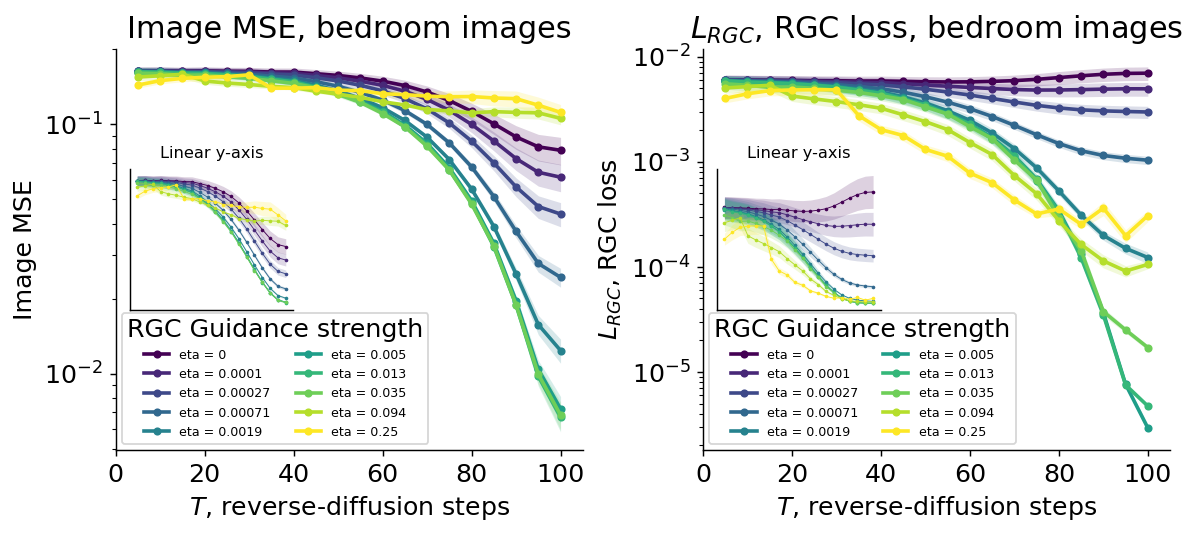

In [71]:
metrics = [
    ('mse_mean', 'mse_sem', 'Image MSE', 'viridis'),
    ('rgc_loss_mean', 'rgc_loss_sem', '$L_{RGC}$, RGC loss', 'viridis'),
]

fig, axes = plt.subplots(1, 2, figsize=(9, 4), constrained_layout=True)
for ax, (mean_column, sem_column, ylabel, cmap_name) in zip(axes, metrics):
    cmap = plt.get_cmap(cmap_name)
    # Preserve the original linear-scale inset while the main panel uses a log y-axis.
    ax_inset = ax.inset_axes([0.03, 0.35, 0.35, 0.35])
    for index, eta in enumerate(etas):
        curve = summary[summary['eta'] == eta].sort_values('T')
        color = cmap(index / max(len(etas) - 1, 1))
        mean = curve[mean_column].to_numpy()
        sem = curve[sem_column].fillna(0).to_numpy()
        ax.plot(curve['T'], mean, color=color, linewidth=2, marker='o', markersize=3.5,
                label='eta = 0' if eta == 0 else f'eta = {eta:.2g}')
        ax.fill_between(curve['T'], np.maximum(mean - sem, 0), mean + sem,
                        color=color, alpha=0.18, linewidth=0)
        ax_inset.plot(curve['T'], mean, color=color, linewidth=0.5, marker='o', markersize=1)
        ax_inset.fill_between(curve['T'], np.maximum(mean - sem, 0), mean + sem,
                              color=color, alpha=0.18, linewidth=0)

    ax.set_title(f'{ylabel}, bedroom images')
    ax.set_xlabel('$T$, reverse-diffusion steps')
    ax.set_ylabel(ylabel)
    ax.set_xlim(timesteps.min()-5, timesteps.max()+5)
    ax.legend(title='RGC Guidance strength', fontsize=7, ncol=2)
    ax_inset.set_title('Linear y-axis', fontsize=9)
    ax_inset.set_xticks([])
    ax_inset.set_yticks([])

for ax in axes:
    ax.set_yscale('log')
plt.show()

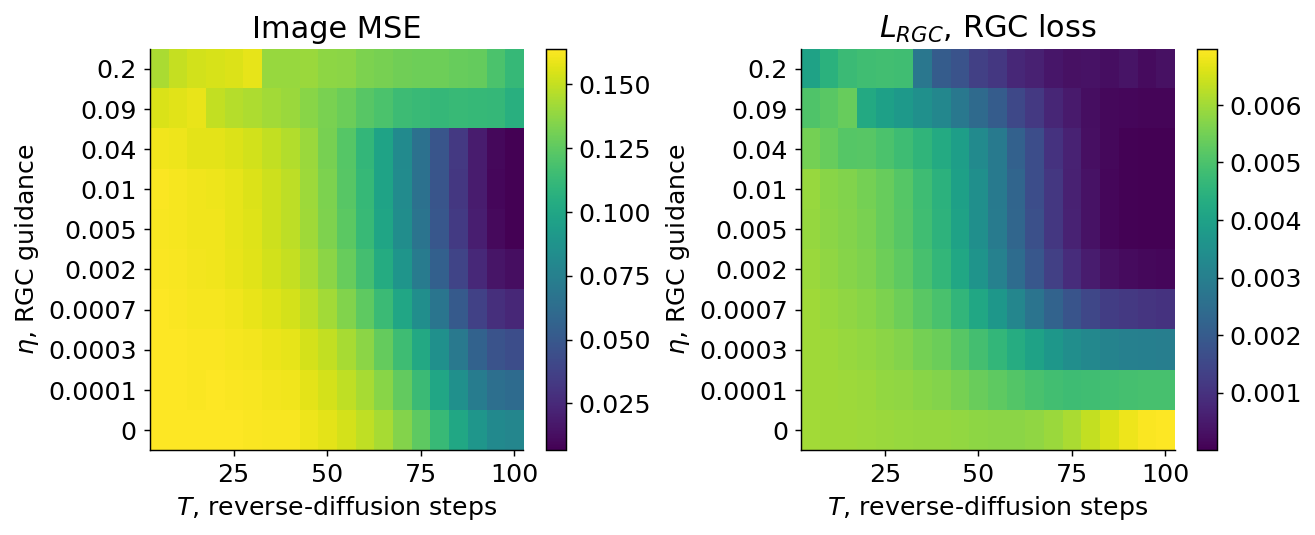

In [72]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
heatmap_specs = [
    ('mse_mean', 'Image MSE', 'viridis'),
    ('rgc_loss_mean', '$L_{RGC}$, RGC loss', 'viridis'),
]

for ax, (column, title, cmap_name) in zip(axes.flat, heatmap_specs):
    matrix = summary.pivot(index='eta', columns='T', values=column).reindex(index=etas, columns=timesteps)
    image = ax.imshow(
        matrix.to_numpy(), aspect='auto', origin='lower', cmap=cmap_name,
        extent=[timesteps.min() - 2.5, timesteps.max() + 2.5, -0.5, len(etas) - 0.5],
    )
    ax.set_title(title)
    ax.set_xlabel('$T$, reverse-diffusion steps')
    ax.set_ylabel(r'$\eta$, RGC guidance')
    ax.set_yticks(np.arange(len(etas)), ['0' if eta == 0 else f'{eta:.1g}' for eta in etas])
    fig.colorbar(image, ax=ax, pad=0.02)

plt.show()

/home/rotation/anaconda3/envs/lnp_torch/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.canvas.print_figure(bytes_io, **kw)


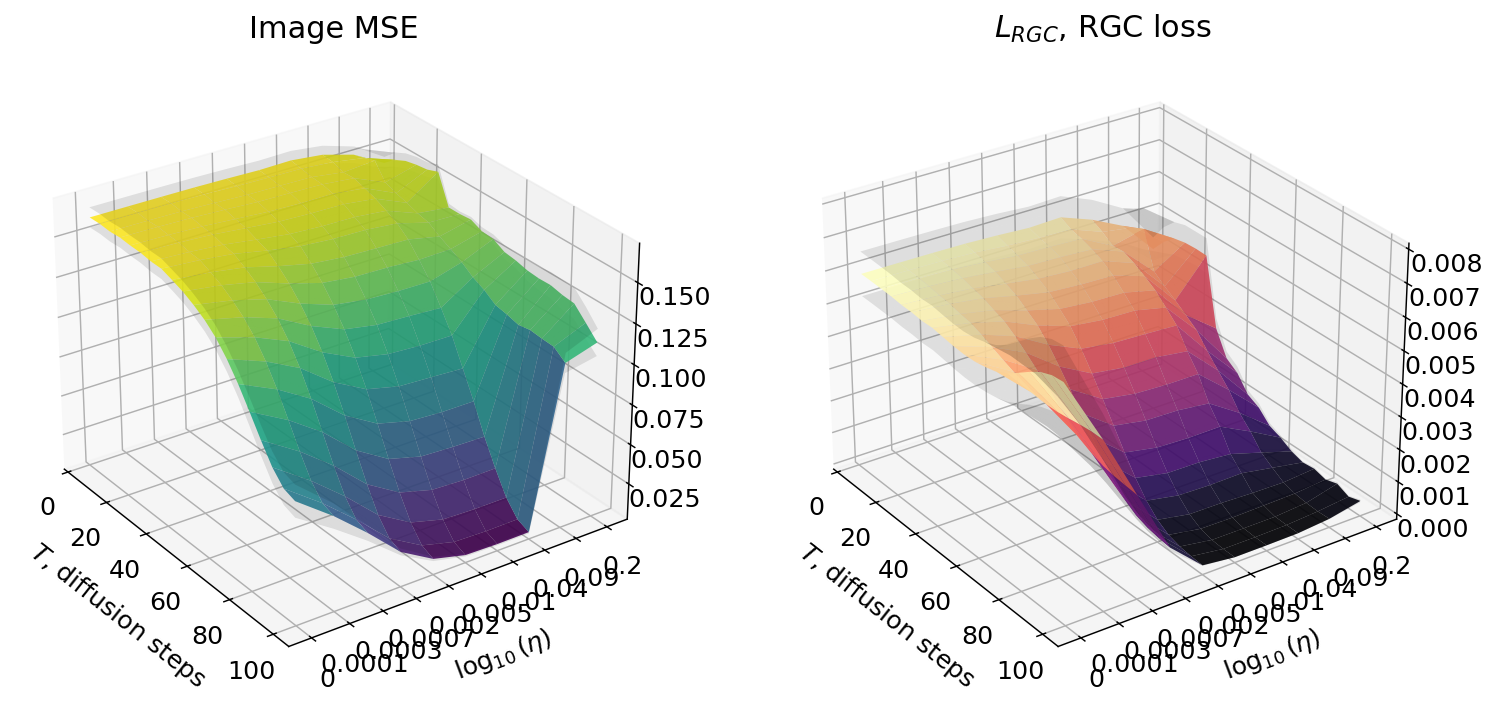

In [73]:
# eta=0 is plotted at a small positive coordinate solely to make a log-like eta axis possible.
positive_etas = etas[etas > 0]
eta_plot = {0.0: positive_etas.min() / 3, **{eta: eta for eta in positive_etas}}
eta_ticks = [eta_plot[eta] for eta in etas]
eta_labels = ['0' if eta == 0 else f'{eta:.1g}' for eta in etas]

T_grid, eta_grid_values = np.meshgrid(timesteps, etas)
eta_grid_log = np.log10(np.vectorize(eta_plot.get)(eta_grid_values))

fig = plt.figure(figsize=(14, 7), constrained_layout=True)
axes = [fig.add_subplot(1, 2, i + 1, projection='3d') for i in range(2)]
for ax, (mean_column, sem_column, title, cmap_name) in zip(
    axes,
    [
        ('mse_mean', 'mse_sem', 'Image MSE', 'viridis'),
        ('rgc_loss_mean', 'rgc_loss_sem', '$L_{RGC}$, RGC loss', 'magma'),
    ],
):
    mean = summary.pivot(index='eta', columns='T', values=mean_column).reindex(index=etas, columns=timesteps).to_numpy()
    sem = summary.pivot(index='eta', columns='T', values=sem_column).reindex(index=etas, columns=timesteps).fillna(0).to_numpy()
    surface = ax.plot_surface(T_grid, eta_grid_log, mean, cmap=cmap_name, edgecolor='none', alpha=0.9)
    # Translucent upper and lower SEM shells communicate uncertainty around the mean surface.
    ax.plot_surface(T_grid, eta_grid_log, mean + sem, color='black', edgecolor='none', alpha=0.10)
    ax.plot_surface(T_grid, eta_grid_log, np.maximum(mean - sem, 0), color='black', edgecolor='none', alpha=0.10)
    ax.set_title(title)
    ax.set_xlabel('$T$, diffusion steps', labelpad=8)
    ax.set_ylabel(r'$\log_{10}(\eta)$', labelpad=9)
    # ax.set_zlabel(title, labelpad=8)
    ax.set_yticks(np.log10(eta_ticks), eta_labels)
    ax.view_init(elev=28, azim=-35)
    # fig.colorbar(surface, ax=ax, shrink=0.62, pad=0.1, label=title)

plt.show()

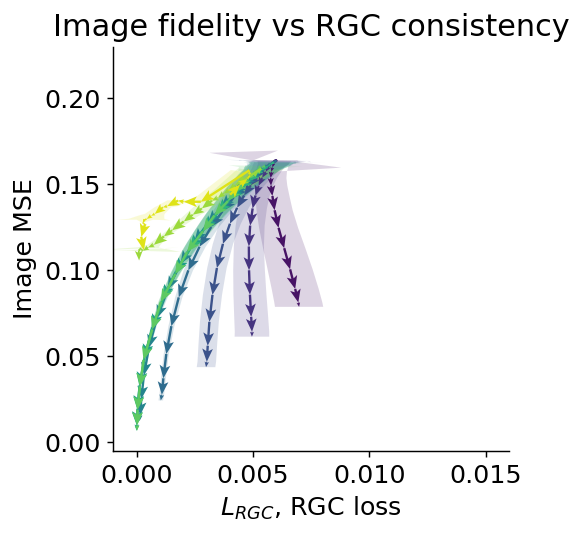

In [74]:
# Each arrowed trajectory follows mean (RGC loss, MSE) as T increases.
# Translucent horizontal and vertical bars show ±1 SEM at each checkpoint.
fig, ax = plt.subplots(figsize=(4, 4), constrained_layout=True)
eta_colors = plt.get_cmap('viridis')(np.linspace(0.05, 0.95, len(etas)))

for eta, color in zip(etas, eta_colors):
    trajectory = summary[summary['eta'] == eta].sort_values('T')
    x = trajectory['rgc_loss_mean'].to_numpy()
    y = trajectory['mse_mean'].to_numpy()
    x_sem = trajectory['rgc_loss_sem'].fillna(0).to_numpy()
    y_sem = trajectory['mse_sem'].fillna(0).to_numpy()

    # Continuous ±1 SEM tube around the mean trajectory.
    # The tube is oriented perpendicular to the local trajectory direction.
    dx_dT = np.gradient(x)
    dy_dT = np.gradient(y)
    tangent_norm = np.hypot(dx_dT, dy_dT)
    tangent_norm = np.maximum(tangent_norm, 1e-12)

    normal_x = -dy_dT / tangent_norm
    normal_y = dx_dT / tangent_norm

    # Propagate independent x/y SEM onto the direction perpendicular to the path.
    normal_sem = np.sqrt((normal_x * x_sem) ** 2 + (normal_y * y_sem) ** 2)

    x_upper = x + normal_sem * normal_x
    y_upper = y + normal_sem * normal_y
    x_lower = x - normal_sem * normal_x
    y_lower = y - normal_sem * normal_y

    ax.fill(np.concatenate([x_upper, x_lower[::-1]]), np.concatenate([y_upper, y_lower[::-1]]), color=color, alpha=0.18, linewidth=0, zorder=1)

    ax.quiver(x[:-1], y[:-1], np.diff(x), np.diff(y), color=color, alpha=1,
              angles='xy', scale_units='xy', scale=1, width=0.006, headwidth=4.5,
              headlength=5.5, headaxislength=4.5, zorder=2)
    ax.plot([], [], color=color, linewidth=2, label=f'eta = {eta:.2g}')

#ax.set_xscale('log')
#ax.set_yscale('log')
ax.set_xlim(-0.001, 0.016)
ax.set_ylim(-0.005, 0.23)
ax.set_xlabel('$L_{RGC}$, RGC loss')
ax.set_ylabel('Image MSE')
ax.set_title('Image fidelity vs RGC consistency')
#ax.legend(title='RGC Guidance strength', fontsize=7, ncol=2)
plt.show()

## Out of distribution (random images)

In [75]:
SEARCH_DIR = Path('hyperparameter_search_outdist')
RESULTS_PATH = SEARCH_DIR / 'results.csv'

results = pd.read_csv(RESULTS_PATH).sort_values(['source_image', 'eta', 'T']).reset_index(drop=True)
expected_columns = {'source_image', 'eta', 'sigma_r', 'T', 'mse', 'final_rgc_loss', 'seed'}
missing_columns = expected_columns.difference(results.columns)
if missing_columns:
    raise ValueError(f'Missing expected CSV columns: {sorted(missing_columns)}')

# take the first 20 images to be consistent with indist images
results = results[results["source_image"].isin(results["source_image"].unique()[:20])]

summary = (
    results.groupby(['eta', 'T'], as_index=False)
    .agg(
        mse_mean=('mse', 'mean'),
        mse_sem=('mse', 'sem'),
        rgc_loss_mean=('final_rgc_loss', 'mean'),
        rgc_loss_sem=('final_rgc_loss', 'sem'),
        n_images=('source_image', 'nunique'),
    )
)

etas = np.sort(summary['eta'].unique())
timesteps = np.sort(summary['T'].unique())
sigmas = np.sort(results['sigma_r'].unique())
n_images = results['source_image'].nunique()
print(f'Loaded {len(results):,} checkpoints from {RESULTS_PATH}')
print(f'Summarizing {n_images} source images | eta values: {len(etas)} | T values: {len(timesteps)} | sigma_r: {sigmas}')

best_mse = summary.loc[summary['mse_mean'].idxmin()]
best_rgc = summary.loc[summary['rgc_loss_mean'].idxmin()]
display(pd.DataFrame([best_mse, best_rgc], index=['Lowest mean MSE', 'Lowest mean RGC loss']))

Loaded 4,000 checkpoints from hyperparameter_search_outdist/results.csv
Summarizing 20 source images | eta values: 10 | T values: 20 | sigma_r: [1.]


,eta,T,mse_mean,mse_sem,rgc_loss_mean,rgc_loss_sem,n_images
Lowest mean MSE,0.013296,100.0,0.005805,0.000855,0.000006,8.643272e-07,20.0
Lowest mean RGC loss,0.005000,100.0,0.006241,0.000950,0.000003,6.104047e-07,20.0


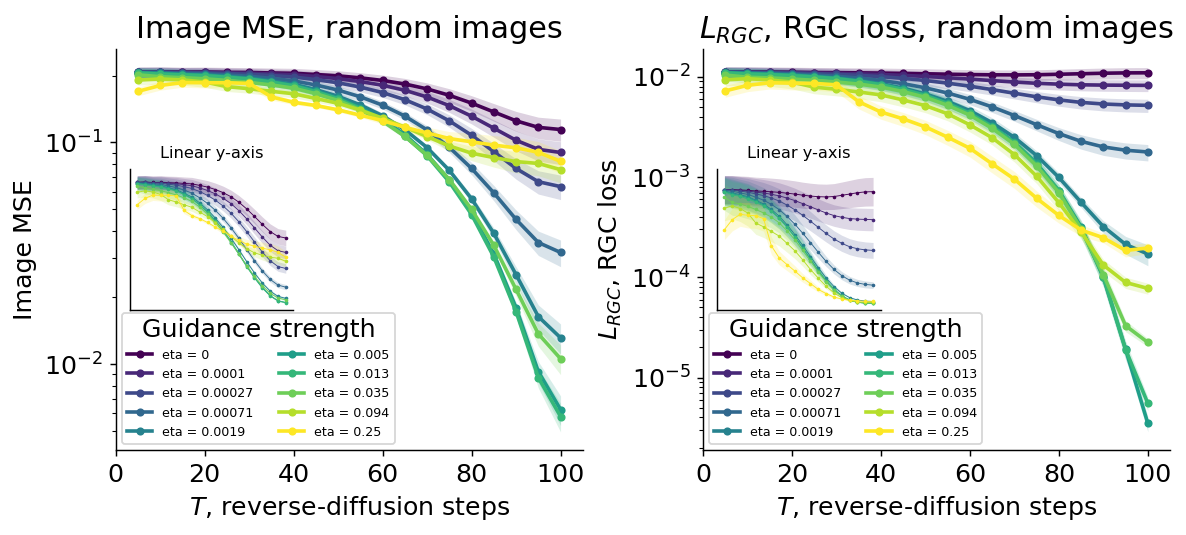

In [76]:
metrics = [
    ('mse_mean', 'mse_sem', 'Image MSE', 'viridis'),
    ('rgc_loss_mean', 'rgc_loss_sem', '$L_{RGC}$, RGC loss', 'viridis'),
]

fig, axes = plt.subplots(1, 2, figsize=(9, 4), constrained_layout=True)
for ax, (mean_column, sem_column, ylabel, cmap_name) in zip(axes, metrics):
    cmap = plt.get_cmap(cmap_name)
    # Preserve the original linear-scale inset while the main panel uses a log y-axis.
    ax_inset = ax.inset_axes([0.03, 0.35, 0.35, 0.35])
    for index, eta in enumerate(etas):
        curve = summary[summary['eta'] == eta].sort_values('T')
        color = cmap(index / max(len(etas) - 1, 1))
        mean = curve[mean_column].to_numpy()
        sem = curve[sem_column].fillna(0).to_numpy()
        ax.plot(curve['T'], mean, color=color, linewidth=2, marker='o', markersize=3.5,
                label='eta = 0' if eta == 0 else f'eta = {eta:.2g}')
        ax.fill_between(curve['T'], np.maximum(mean - sem, 0), mean + sem,
                        color=color, alpha=0.18, linewidth=0)
        ax_inset.plot(curve['T'], mean, color=color, linewidth=0.5, marker='o', markersize=1)
        ax_inset.fill_between(curve['T'], np.maximum(mean - sem, 0), mean + sem,
                              color=color, alpha=0.18, linewidth=0)

    ax.set_title(f'{ylabel}, random images')
    ax.set_xlabel('$T$, reverse-diffusion steps')
    ax.set_ylabel(ylabel)
    ax.set_xlim(timesteps.min()-5, timesteps.max()+5)
    ax.legend(title='Guidance strength', fontsize=7, ncol=2)
    ax_inset.set_title('Linear y-axis', fontsize=9)
    ax_inset.set_xticks([])
    ax_inset.set_yticks([])

for ax in axes:
    ax.set_yscale('log')
plt.show()

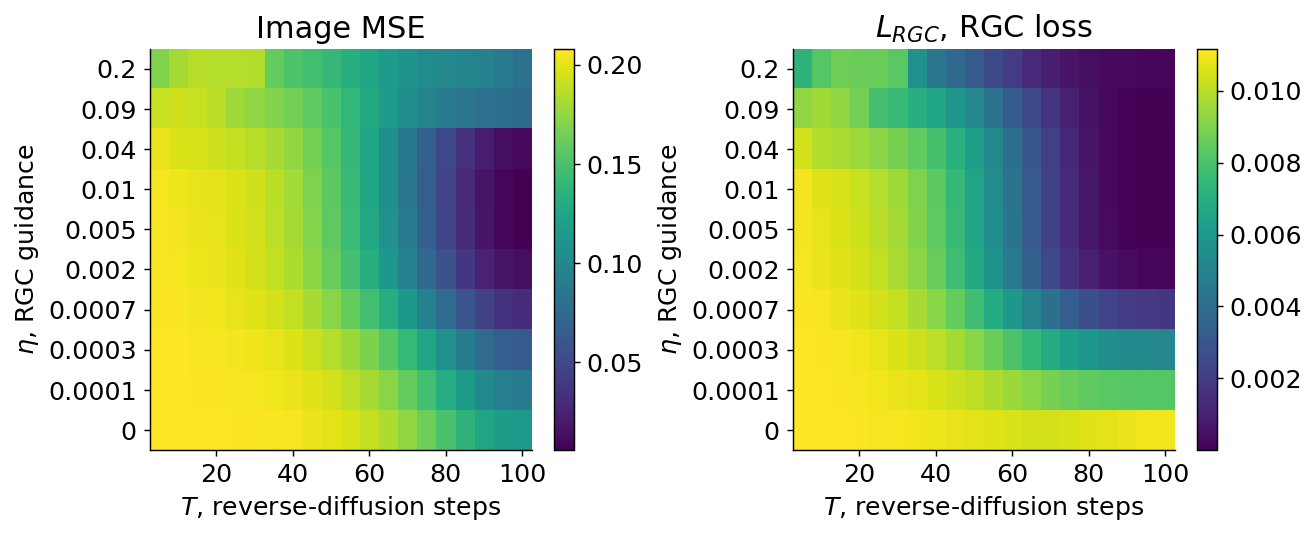

In [77]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
heatmap_specs = [
    ('mse_mean', 'Image MSE', 'viridis'),
    ('rgc_loss_mean', '$L_{RGC}$, RGC loss', 'viridis'),
]

for ax, (column, title, cmap_name) in zip(axes.flat, heatmap_specs):
    matrix = summary.pivot(index='eta', columns='T', values=column).reindex(index=etas, columns=timesteps)
    image = ax.imshow(
        matrix.to_numpy(), aspect='auto', origin='lower', cmap=cmap_name,
        extent=[timesteps.min() - 2.5, timesteps.max() + 2.5, -0.5, len(etas) - 0.5],
    )
    ax.set_title(title)
    ax.set_xlabel('$T$, reverse-diffusion steps')
    ax.set_ylabel(r'$\eta$, RGC guidance')
    ax.set_yticks(np.arange(len(etas)), ['0' if eta == 0 else f'{eta:.1g}' for eta in etas])
    fig.colorbar(image, ax=ax, pad=0.02)

plt.show()

/home/rotation/anaconda3/envs/lnp_torch/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.canvas.print_figure(bytes_io, **kw)


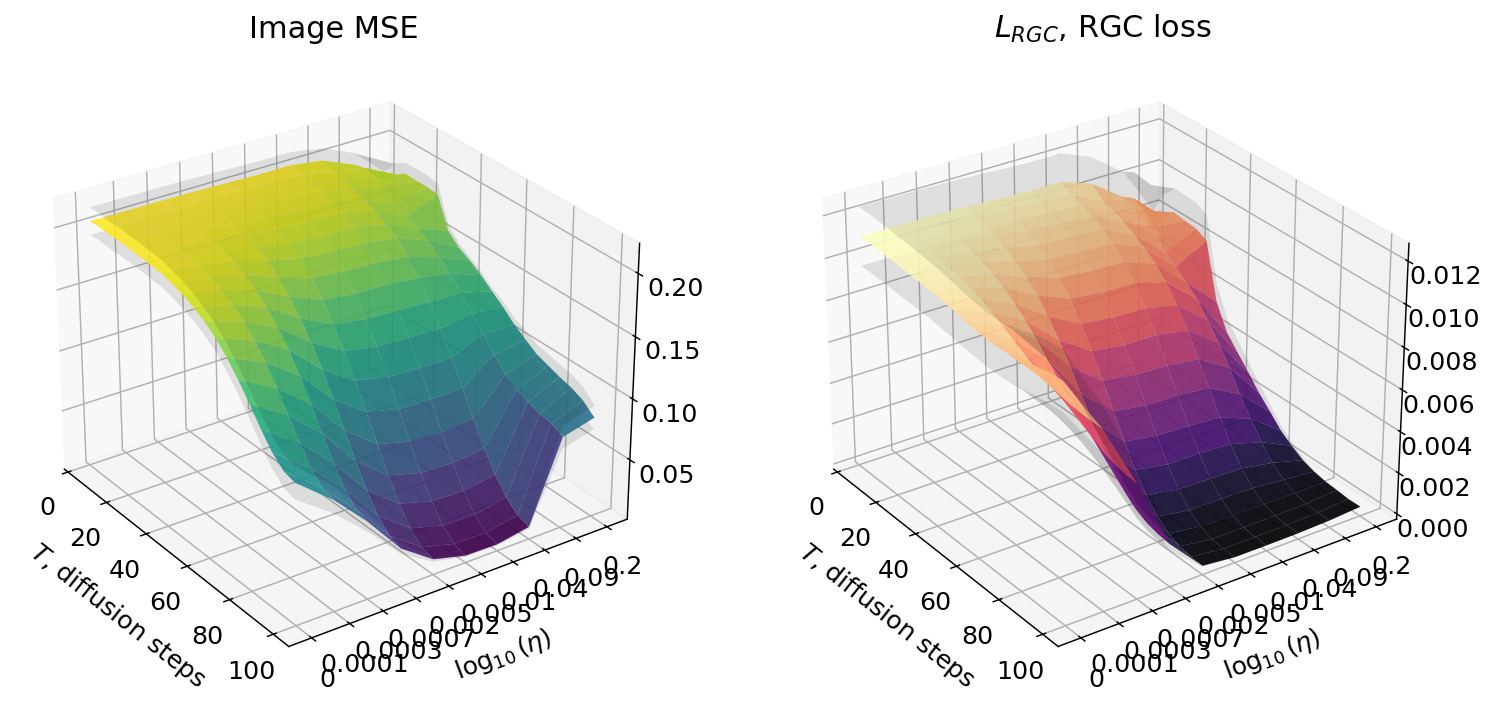

In [78]:
# eta=0 is plotted at a small positive coordinate solely to make a log-like eta axis possible.
positive_etas = etas[etas > 0]
eta_plot = {0.0: positive_etas.min() / 3, **{eta: eta for eta in positive_etas}}
eta_ticks = [eta_plot[eta] for eta in etas]
eta_labels = ['0' if eta == 0 else f'{eta:.1g}' for eta in etas]

T_grid, eta_grid_values = np.meshgrid(timesteps, etas)
eta_grid_log = np.log10(np.vectorize(eta_plot.get)(eta_grid_values))

fig = plt.figure(figsize=(14, 7), constrained_layout=True)
axes = [fig.add_subplot(1, 2, i + 1, projection='3d') for i in range(2)]
for ax, (mean_column, sem_column, title, cmap_name) in zip(
    axes,
    [
        ('mse_mean', 'mse_sem', 'Image MSE', 'viridis'),
        ('rgc_loss_mean', 'rgc_loss_sem', '$L_{RGC}$, RGC loss', 'magma'),
    ],
):
    mean = summary.pivot(index='eta', columns='T', values=mean_column).reindex(index=etas, columns=timesteps).to_numpy()
    sem = summary.pivot(index='eta', columns='T', values=sem_column).reindex(index=etas, columns=timesteps).fillna(0).to_numpy()
    surface = ax.plot_surface(T_grid, eta_grid_log, mean, cmap=cmap_name, edgecolor='none', alpha=0.9)
    # Translucent upper and lower SEM shells communicate uncertainty around the mean surface.
    ax.plot_surface(T_grid, eta_grid_log, mean + sem, color='black', edgecolor='none', alpha=0.10)
    ax.plot_surface(T_grid, eta_grid_log, np.maximum(mean - sem, 0), color='black', edgecolor='none', alpha=0.10)
    ax.set_title(title)
    ax.set_xlabel('$T$, diffusion steps', labelpad=8)
    ax.set_ylabel(r'$\log_{10}(\eta)$', labelpad=9)
    # ax.set_zlabel(title, labelpad=8)
    ax.set_yticks(np.log10(eta_ticks), eta_labels)
    ax.view_init(elev=28, azim=-35)
    # fig.colorbar(surface, ax=ax, shrink=0.62, pad=0.1, label=title)

plt.show()

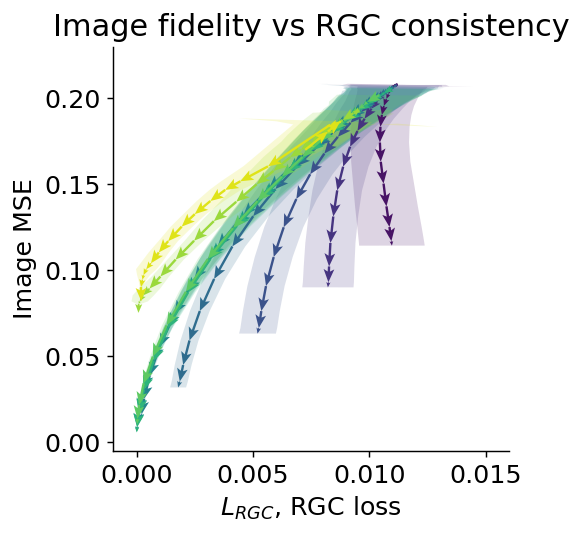

In [79]:
# Each arrowed trajectory follows mean (RGC loss, MSE) as T increases.
# Translucent horizontal and vertical bars show ±1 SEM at each checkpoint.
fig, ax = plt.subplots(figsize=(4, 4), constrained_layout=True)
eta_colors = plt.get_cmap('viridis')(np.linspace(0.05, 0.95, len(etas)))

for eta, color in zip(etas, eta_colors):
    trajectory = summary[summary['eta'] == eta].sort_values('T')
    x = trajectory['rgc_loss_mean'].to_numpy()
    y = trajectory['mse_mean'].to_numpy()
    x_sem = trajectory['rgc_loss_sem'].fillna(0).to_numpy()
    y_sem = trajectory['mse_sem'].fillna(0).to_numpy()

    # Continuous ±1 SEM tube around the mean trajectory.
    # The tube is oriented perpendicular to the local trajectory direction.
    dx_dT = np.gradient(x)
    dy_dT = np.gradient(y)
    tangent_norm = np.hypot(dx_dT, dy_dT)
    tangent_norm = np.maximum(tangent_norm, 1e-12)

    normal_x = -dy_dT / tangent_norm
    normal_y = dx_dT / tangent_norm

    # Propagate independent x/y SEM onto the direction perpendicular to the path.
    normal_sem = np.sqrt((normal_x * x_sem) ** 2 + (normal_y * y_sem) ** 2)

    x_upper = x + normal_sem * normal_x
    y_upper = y + normal_sem * normal_y
    x_lower = x - normal_sem * normal_x
    y_lower = y - normal_sem * normal_y

    ax.fill(np.concatenate([x_upper, x_lower[::-1]]), np.concatenate([y_upper, y_lower[::-1]]), color=color, alpha=0.18, linewidth=0, zorder=1)

    ax.quiver(x[:-1], y[:-1], np.diff(x), np.diff(y), color=color, alpha=1,
              angles='xy', scale_units='xy', scale=1, width=0.006, headwidth=4.5,
              headlength=5.5, headaxislength=4.5, zorder=2)
    ax.plot([], [], color=color, linewidth=2, label=f'eta = {eta:.2g}')

# ax.set_xscale('log')
# ax.set_yscale('log')
ax.set_xlim(-0.001, 0.016)
ax.set_ylim(-0.005, 0.23)
ax.set_xlabel('$L_{RGC}$, RGC loss')
ax.set_ylabel('Image MSE')
ax.set_title('Image fidelity vs RGC consistency')
#ax.legend(bbox_to_anchor=(0.5, -0.15), ncol=5, loc='upper center', fontsize=6)
plt.show()

## Reconstruction images

Folder-mode grid searches intentionally save only aggregate statistics, so there is no reconstruction-image grid for this analysis. Run the single-image search mode when qualitative reconstruction panels are needed.